# Previsão de Atrasos em Entregas 🚚

## Descrição do Problema

A EntregaCerta é uma empresa fictícia de comércio eletrônico que atende clientes em diferentes regiões do Brasil. A empresa trabalha com múltiplas transportadoras e modalidades de envio.

Recentemente, a equipe de operações identificou dificuldades em cumprir os prazos de entrega prometidos aos clientes. Como os atrasos podem comprometer a satisfação dos consumidores e gerar custos operacionais, a empresa busca compreender quais fatores estão associados a esse problema e identificar antecipadamente os pedidos com maior risco de atraso.

Para isso, pretende utilizar técnicas de Ciência de Dados e Machine Learning, além de ferramentas de visualização, como o Power BI, para apoiar a tomada de decisões e melhorar o planejamento logístico.

## Base de Dados

A base de dados é uma base sintética, gerada pelo ChatGPT, composta por aproximadamente 30 mil registros de pedidos de uma empresa fictícia de comércio eletrônico. Ela possui informações relacionadas às entregas de produtos para diferentes regiões do Brasil, incluindo características dos pedidos, categorias de produtos, transportadoras, modalidades de envio, distâncias percorridas, prazos prometidos, disponibilidade de estoque e condições operacionais, como congestionamento das rotas e previsão de chuva. Além da variável alvo 'atrasou', que registra 0 para não e 1 para sim.

## Importações

In [66]:
import pandas as pd
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import make_column_transformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

## 1. Carregamento e Exploração de Dados

### 1.1 Carregamento da Base de Dados

In [2]:
df = pd.read_csv('../data/raw/delivery_orders.csv')
df.head()

,pedido_id,data_pedido,regiao_destino,estado_destino,categoria_produto,transportadora,modalidade_envio,distancia_km,valor_pedido_brl,estoque_disponivel,carga_centro_distribuicao_pct,chuva_prevista_mm,congestionamento_rota,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,dias_atraso,data_entrega
0,PED000001,2024-04-09,Nordeste,PB,Eletrônicos,ViaExpress,Padrão,956,55.88,Sim,59,6.9,Alto,1.5,5,0,0,0,2024-04-14
1,PED000002,2024-04-14,Sudeste,SP,Beleza,ViaExpress,Econômica,402,36.89,Sim,76,0.5,Baixo,4.4,6,1,0,0,2024-04-20
2,PED000003,2024-11-06,Nordeste,MA,Beleza,BrasilLog,Econômica,541,169.20,Não,78,4.9,Moderado,3.9,7,0,1,5,2024-11-18
3,PED000004,2024-01-02,Sudeste,RJ,Eletrônicos,BrasilLog,Padrão,3302,103.07,Sim,74,0.4,Baixo,4.7,14,0,1,5,2024-01-21
4,PED000005,2025-05-20,Sudeste,MG,Casa e decoração,RotaSul,Expressa,1447,62.23,Sim,69,9.0,Baixo,3.2,5,0,0,0,2025-05-25


### 1.2 Visão Geral dos Dados

In [3]:
df.shape

(30000, 19)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   pedido_id                      30000 non-null  object 
 1   data_pedido                    30000 non-null  object 
 2   regiao_destino                 30000 non-null  object 
 3   estado_destino                 30000 non-null  object 
 4   categoria_produto              30000 non-null  object 
 5   transportadora                 30000 non-null  object 
 6   modalidade_envio               30000 non-null  object 
 7   distancia_km                   30000 non-null  int64  
 8   valor_pedido_brl               30000 non-null  float64
 9   estoque_disponivel             30000 non-null  object 
 10  carga_centro_distribuicao_pct  30000 non-null  int64  
 11  chuva_prevista_mm              30000 non-null  float64
 12  congestionamento_rota          30000 non-null 

In [5]:
df.describe()

,distancia_km,valor_pedido_brl,carga_centro_distribuicao_pct,chuva_prevista_mm,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,dias_atraso
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000
mean,880.945333,87.535554,67.728900,9.620873,3.256920,5.912267,0.283900,0.448433,1.792833
std,603.260141,88.509881,16.532122,8.759490,1.891821,2.786161,0.450896,0.497342,2.393750
min,15.000000,25.000000,15.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,434.000000,33.510000,57.000000,3.300000,1.900000,4.000000,0.000000,0.000000,0.000000
50%,746.000000,59.945000,68.000000,7.200000,3.200000,6.000000,0.000000,0.000000,0.000000
75%,1181.000000,106.235000,79.000000,13.325000,4.500000,7.000000,1.000000,1.000000,4.000000
max,3500.000000,1570.700000,100.000000,90.000000,10.900000,20.000000,1.000000,1.000000,7.000000


In [6]:
df.isnull().sum()

pedido_id                        0
data_pedido                      0
regiao_destino                   0
estado_destino                   0
categoria_produto                0
transportadora                   0
modalidade_envio                 0
distancia_km                     0
valor_pedido_brl                 0
estoque_disponivel               0
carga_centro_distribuicao_pct    0
chuva_prevista_mm                0
congestionamento_rota            0
lead_time_fornecedor_dias        0
dias_prometidos                  0
fim_de_semana                    0
atrasou                          0
dias_atraso                      0
data_entrega                     0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.select_dtypes(include="object").nunique()

pedido_id                30000
data_pedido                730
regiao_destino               5
estado_destino              27
categoria_produto            6
transportadora               4
modalidade_envio             3
estoque_disponivel           2
congestionamento_rota        3
data_entrega               746
dtype: int64

De acordo com a visão geral dos dados, destaca-se que:
1. possui 30.000 registros e 19 colunas.
2. os tipos de dados de cada coluna variam entre object, int e float
3. existem atrasos máximos de 7 dias e mínimos de 0 dias, com desvio padrão de aproximadamente 2 dias de atraso
4. não foram identificados valores nulos e nem duplicados. Destaca-se que a base sintética foi ferada sem esses ocorrências, a fim de focar nas etapas de análise e modelagem preditiva.

### 1.3 Análise Exploratória

#### 1.3.1 Distribuição das Distâncias de Entrega

In [9]:
fig = px.histogram(
    df,
    x="distancia_km",
    nbins=40,
    title="Distribuição das Distâncias de Entrega",
    labels={
        "distancia_km": "Distância (km)",
        "count": "Quantidade de pedidos"
    },
    template="plotly_white"
)

fig.update_layout(
    title_x=0.5,
    xaxis_title="Distância (km)",
    yaxis_title="Quantidade de pedidos"
)

fig.show()

A visualização da Distribuição de Distâncias nos permite analisar que a quantidade de pedidos está concentrada em distâncias menores, com uma leve cauda indicando que quanto maior a distância, menores são os pedidos. 

In [10]:
df["distancia_km"].value_counts().head()

distancia_km
3500    67
539     41
374     40
485     40
378     39
Name: count, dtype: int64

In [11]:
df["distancia_km"].value_counts().sort_index().tail(10)

distancia_km
3455     1
3456     1
3460     1
3462     1
3470     1
3480     1
3481     1
3489     1
3497     1
3500    67
Name: count, dtype: int64

Algo que chamou a atenção foi que a distância de 3500 km possui muitos registros a mais que as distâncias próximas a ela, o que pode indicar um limite aplicado na geração da base sintética, em que se considerou 3500 km como limite superior. Porém, como esse valor corresponde a uma parcela muito pequena em comparação com os demais, não há a necessidade de removê-lo.

#### 1.3.2 Distribuição de Valores de Pedido

In [12]:
fig = px.histogram(
    df,
    x="valor_pedido_brl",
    nbins=50,
    title="Distribuição dos Valores de Pedido",
    labels={
        "valor_pedido_brl": "Valor do Pedido (R$)",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_xaxes(range=[0, 500])
fig.update_layout(title_x=0.5)

fig.show()

Neste histograma, nota-se que, assim como as distâncias, os valores baixos são os que mais se concentram nos pedidos, com mais de 12 mil pedidos na faixa de 0 a 50 reais. 
Uma observação importante é que, para visualizar melhor onde há a maior distribuição, a visualização foi diminuída em até 500 reais, mas, ao interagir com o gráfico, é possível analisar que existem valores até perto de R$1.600.

#### 1.3.3 Distribuição de Prazos Prometidos

In [13]:
fig = px.histogram(
    df,
    x="dias_prometidos",
    title="Frequência dos Prazos Prometidos",
    labels={
        "dias_prometidos": "Dias Prometidos",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.update_xaxes(dtick=1)

fig.show()

Segundo o gráfico acima, há uma grande concentração de pedidos entre 3 e 7 dias prometidos pela empresa. A relação entre os dias prometidos e os atrasos, será observada em um momento posterior.

#### 1.3.4 Distribuição de Tempo de Fornecimento dos Produtos

In [14]:
fig = px.histogram(
    df,
    x="lead_time_fornecedor_dias",
    title="Distribuição do Tempo de Fornecimento dos Produtos",
    labels={
        "lead_time_fornecedor_dias": "Tempo de Fornecimento (dias)",
        "count": "Quantidade de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.update_xaxes(dtick=1)

fig.show()

Com essa visualização, percebe-se que pedidos com tempo de fornecimento de 0 dias se destacam. Isso indica que não houve tempo de espera para o abastecimento dos produtos.

#### 1.3.5 Verificação de Outliers

In [15]:
colunas = [
    "distancia_km",
    "valor_pedido_brl",
    "chuva_prevista_mm",
    "lead_time_fornecedor_dias",
    "dias_prometidos"
]

for coluna in colunas:
    fig = px.box(
        df,
        y=coluna,
        title=f"Distribuição de {coluna}",
        template="plotly_white"
    )

    fig.update_layout(title_x=0.5)
    fig.show()

Existe um grande número de possíveis outliers principalmente nas variáveis de distância e valor do pedido, o que condiz com o que foi analisado anteriormente, onde há uma concetração de pedidos com distância e valores menores. Ademais, também nota-se outros possíveis outliers na previsão de chuvas em mm. Porém, essas ocorrências serão mantidas inicialmente, considerando que podem representar características legítimas dos pedidos. 

#### 1.3.6 Análise das Variáveis Categóricas

In [16]:
df["modalidade_envio"].value_counts()

modalidade_envio
Padrão       13123
Econômica    11391
Expressa      5486
Name: count, dtype: int64

In [17]:
df["congestionamento_rota"].value_counts()

congestionamento_rota
Moderado    13793
Baixo       10222
Alto         5985
Name: count, dtype: int64

In [18]:
df["regiao_destino"].value_counts()

regiao_destino
Sudeste         11867
Nordeste         7984
Sul              5095
Centro-Oeste     2636
Norte            2418
Name: count, dtype: int64

Através dessas contagens de algumas variáveis categóricas, nota-se que:
1. as modalidades de envio mais utilizadas são Padrão e Econômica
2. o congestionamento Moderado se destaca, posteriormente será analisado se s condições de congestionamento estão associadas à ocorrência de atrasos
3. a região com mais pedidos é a Sudeste e a com menos é a Norte. Essa diferença pode estar relacionada à distribuição geográfica da demanda, mas não é possível determinar sua causa apenas com os dados disponíveis.

### 1.4 Análise da Variável-Alvo

In [19]:
contagem = df["atrasou"].value_counts().sort_index()

percentual = df["atrasou"].value_counts(normalize=True).sort_index() * 100

dados = pd.DataFrame({
    "Situação": ["Sem atraso", "Com atraso"],
    "Quantidade": contagem.values,
    "Percentual": percentual.values
})

fig = px.bar(
    dados,
    x="Situação",
    y="Percentual",
    text=dados["Percentual"].round(1).astype(str) + "%",
    title="Distribuição da Variável-Alvo",
    labels={
        "Situação": "Situação do Pedido",
        "Percentual": "Percentual de Pedidos"
    },
    template="plotly_white"
)

fig.update_layout(title_x=0.5)
fig.show()

Observa-se que a porcentagem de pedidos com atraso totaliza 44.8%, o que indica uma grande proporção. Isso reforça a necessidade de investigar posteriormente sua relação com outras características, para identificar as possíveis causas e realizar as previsões. 

## 2. Preparação dos Dados

### 2.1 Remoção de Variáveis Irrelevantes

In [20]:
df.columns

Index(['pedido_id', 'data_pedido', 'regiao_destino', 'estado_destino',
       'categoria_produto', 'transportadora', 'modalidade_envio',
       'distancia_km', 'valor_pedido_brl', 'estoque_disponivel',
       'carga_centro_distribuicao_pct', 'chuva_prevista_mm',
       'congestionamento_rota', 'lead_time_fornecedor_dias', 'dias_prometidos',
       'fim_de_semana', 'atrasou', 'dias_atraso', 'data_entrega'],
      dtype='object')

In [21]:
df = df.drop(columns=['pedido_id', 'dias_atraso', 'data_entrega'])

In [22]:
df.columns

Index(['data_pedido', 'regiao_destino', 'estado_destino', 'categoria_produto',
       'transportadora', 'modalidade_envio', 'distancia_km',
       'valor_pedido_brl', 'estoque_disponivel',
       'carga_centro_distribuicao_pct', 'chuva_prevista_mm',
       'congestionamento_rota', 'lead_time_fornecedor_dias', 'dias_prometidos',
       'fim_de_semana', 'atrasou'],
      dtype='object')

As variáveis pedido_id, dias_atraso e data_entrega foram removidas. As duas últimas guardam informações posteriores a entrega, portanto não são adequadas para serem preditoras, pois poderiam contribuir para o data leakage.

### 2.2 Tratamento de Variáveis Categóricas

In [23]:
df.select_dtypes(include='object').columns

Index(['data_pedido', 'regiao_destino', 'estado_destino', 'categoria_produto',
       'transportadora', 'modalidade_envio', 'estoque_disponivel',
       'congestionamento_rota'],
      dtype='object')

In [24]:
df.select_dtypes(include='object').nunique()

data_pedido              730
regiao_destino             5
estado_destino            27
categoria_produto          6
transportadora             4
modalidade_envio           3
estoque_disponivel         2
congestionamento_rota      3
dtype: int64

In [25]:
df["estoque_disponivel"].unique()

array(['Sim', 'Não'], dtype=object)

Como a variável estoque_disponível possui apenas 2 valores, será aplicada uma codificação binária, ao invés de utilizar OneHotEnconding como nas demais.

In [26]:
df['estoque_disponivel'] = df['estoque_disponivel'].map({
    'Sim': 1,
    'Não': 0
})
df['estoque_disponivel']

0        1
1        1
2        0
3        1
4        1
        ..
29995    1
29996    1
29997    0
29998    1
29999    1
Name: estoque_disponivel, Length: 30000, dtype: int64

In [27]:
df['data_pedido'].head()

0    2024-04-09
1    2024-04-14
2    2024-11-06
3    2024-01-02
4    2025-05-20
Name: data_pedido, dtype: object

A variável data_pedido precisa ser convertida para date_time. Porém, como o enconder não lida com datas, serão extraídas informações de mês do pedido e dia da semana, pois assim é possível tratá-las no OneHot sem perder informações que possam ser relevantes.

In [28]:
df['data_pedido'] = pd.to_datetime(df['data_pedido'])

df['mes_pedido'] = df['data_pedido'].dt.month
df['dia_semana_pedido'] = df['data_pedido'].dt.dayofweek

df = df.drop(columns=['data_pedido'])
df.head()

,regiao_destino,estado_destino,categoria_produto,transportadora,modalidade_envio,distancia_km,valor_pedido_brl,estoque_disponivel,carga_centro_distribuicao_pct,chuva_prevista_mm,congestionamento_rota,lead_time_fornecedor_dias,dias_prometidos,fim_de_semana,atrasou,mes_pedido,dia_semana_pedido
0,Nordeste,PB,Eletrônicos,ViaExpress,Padrão,956,55.88,1,59,6.9,Alto,1.5,5,0,0,4,1
1,Sudeste,SP,Beleza,ViaExpress,Econômica,402,36.89,1,76,0.5,Baixo,4.4,6,1,0,4,6
2,Nordeste,MA,Beleza,BrasilLog,Econômica,541,169.20,0,78,4.9,Moderado,3.9,7,0,1,11,2
3,Sudeste,RJ,Eletrônicos,BrasilLog,Padrão,3302,103.07,1,74,0.4,Baixo,4.7,14,0,1,1,1
4,Sudeste,MG,Casa e decoração,RotaSul,Expressa,1447,62.23,1,69,9.0,Baixo,3.2,5,0,0,5,1


In [29]:
colunas_categoricas = ['regiao_destino', 'estado_destino', 'categoria_produto',
                       'transportadora', 'modalidade_envio', 'congestionamento_rota', 
                       'mes_pedido', 'dia_semana_pedido']

one_hot = make_column_transformer(
    (OneHotEncoder(
        handle_unknown='ignore'
    ), colunas_categoricas),
    remainder='passthrough',
    sparse_threshold=0
)

Foi aplicado o OneHotEnconder nas variáveis categóricas, e só será executado após dividir os dados de treino e teste e selecionar as variáveis preditoras, para que não haja data leakage.

### 2.3 Normalização das Variáveis Numéricas

In [30]:
colunas_numericas = [
    'distancia_km',
    'valor_pedido_brl',
    'carga_centro_distribuicao_pct',
    'chuva_prevista_mm',
    'lead_time_fornecedor_dias',
    'dias_prometidos'
]

In [31]:
scaler = MinMaxScaler()

Assim como nas variáveis categóricas, as colunas numéricas foram separadas e foi implementado o scaler, que será executado somente após dividir os dados e escolher as variáveis preditoras.

### 2.4 Divisão dos Dados em Treino e Teste

In [32]:
X = df.drop(columns=['atrasou'])
y = df['atrasou']

In [33]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [34]:
print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

print("\nDistribuição da variável-alvo:")
print("Treinamento:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTeste:")
print(y_test.value_counts(normalize=True) * 100)

Treinamento: (24000, 16)
Teste: (6000, 16)

Distribuição da variável-alvo:
Treinamento:
atrasou
0    55.158333
1    44.841667
Name: proportion, dtype: float64

Teste:
atrasou
0    55.15
1    44.85
Name: proportion, dtype: float64


Foram separados 80% dos dados para treino e 20% para teste. A variável alvo ficou com uma distribuição de aproximadamente 55% para não e 44% para sim, em ambos treino e teste.

## 3. Análise e Seleção de Variáveis

### 3.1 Análise de Correlação

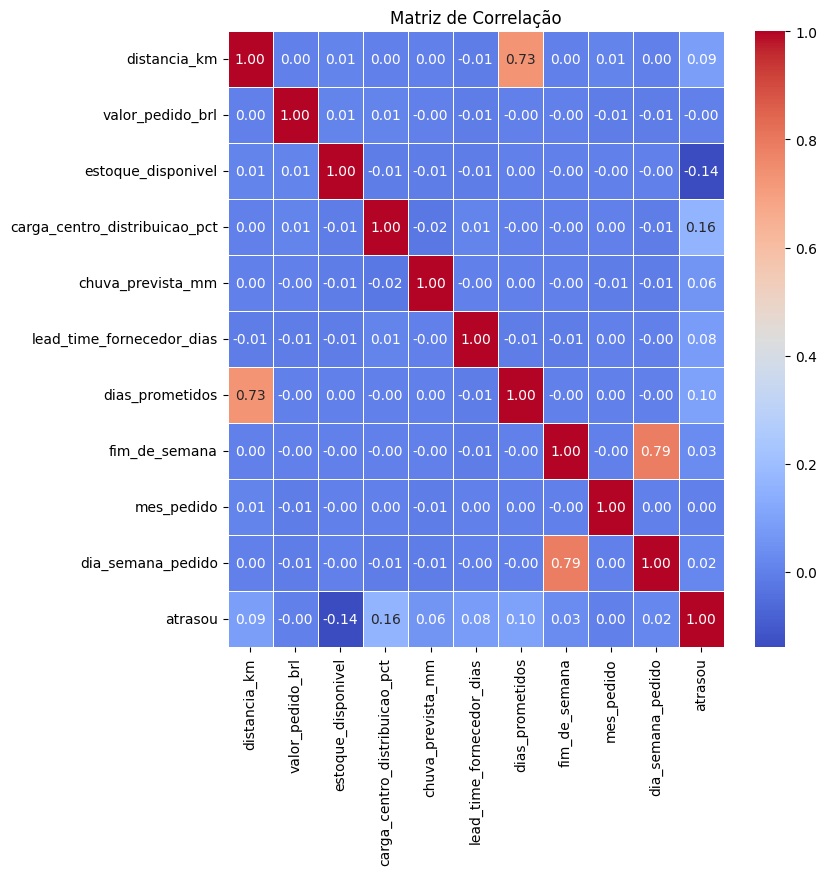

In [35]:
correlation_matrix = pd.concat([X_train, y_train], axis=1).corr(numeric_only=True).round(2)

fig, ax = plt.subplots(figsize=(8, 8))

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    linewidths=.5,
    ax=ax,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de Correlação')
plt.show()

De acordo com a análise da matrix de correlação, identificou-se que:
* carga_centro_distribuicao_pct apresenta a maior correlação positiva, indicando uma associação positiva fraca com a ocorrência de atrasos.
* estoque_disponivel apresenta correlação negativa, sugerindo que pedidos com estoque disponível tendem a apresentar menor ocorrência de atrasos.
* dias_prometidos, distancia_km, lead_time_fornecedor_dias e chuva_prevista_mm apresentam baixas correlações positivas.

### 3.2 Relação entre as Variáveis e a Variável-Alvo

#### 3.2.1 Variáveis Numéricas

In [36]:
colunas_numericas

['distancia_km',
 'valor_pedido_brl',
 'carga_centro_distribuicao_pct',
 'chuva_prevista_mm',
 'lead_time_fornecedor_dias',
 'dias_prometidos']

In [37]:
df_train = X_train.copy()
df_train['atrasou'] = y_train

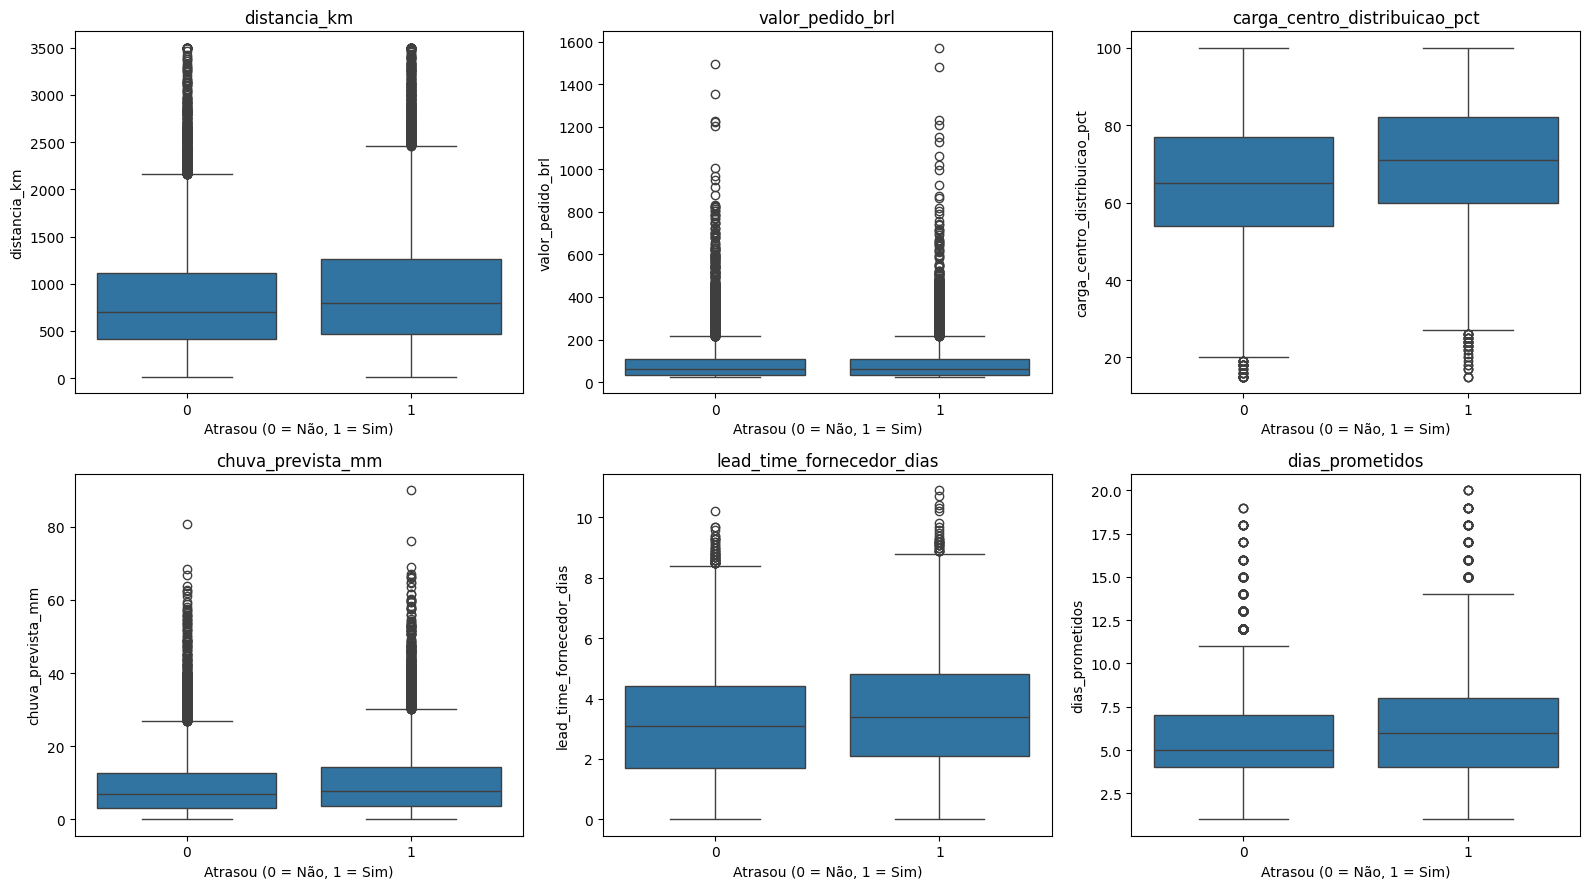

In [38]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for coluna, ax in zip(colunas_numericas, axes.flatten()):
    sns.boxplot(
        data=df_train,
        x='atrasou',
        y=coluna,
        ax=ax
    )
    ax.set_title(coluna)
    ax.set_xlabel('Atrasou (0 = Não, 1 = Sim)')

plt.tight_layout()
plt.show()

Análise de cada boxplot:
- distancia_km: a mediana é um pouco maior nos pedidos atrasados, mas há grande sobreposição entre as distribuições, então distancia possui baixa correlação com 'atrasou'.
- valor_pedido_brl: as medianas próximas indicam que possui baixa correlação com a variável alvo.
- carga_centro_distribuicao_pct: a mediana nos atrasos é a maior de todos os outros boxplots, logo a carga possui mais correlação com o problema do que as demais.
- chuva_prevista_mm: a mediana de 1 está ligeiramente superior, porém as distribuições apresentam sobreposição, logo há uma baixa correlação com o alvo.
- lead_time_fornecedor_dias: assim como a distância e a chuva prevista, a lead_time também apresenta sobreposição, apesar da mediana de 1 estar levemente acima.
- dias_prometidos: a mediana é superior aos pedidos de atraso, indicando também alguma correlação com a variável alvo.

#### 3.2.2 Variáveis Categóricas

In [39]:
variaveis_categoricas = [
    'regiao_destino',
    'estado_destino',
    'categoria_produto',
    'transportadora',
    'modalidade_envio',
    'congestionamento_rota',
    'estoque_disponivel',
    'fim_de_semana',
    'mes_pedido',
    'dia_semana_pedido'
]

for coluna in variaveis_categoricas:
    df_proporcao = (
        df_train.groupby(coluna)['atrasou']
        .mean()
        .reset_index()
    )
    
    df_proporcao['atrasou'] = df_proporcao['atrasou'] * 100
    
    fig = px.bar(
        df_proporcao,
        x=coluna,
        y='atrasou',
        title=f'Proporção de Atrasos por {coluna}',
        labels={
            coluna: coluna.replace('_', ' ').title(),
            'atrasou': 'Pedidos Atrasados (%)'
        },
        text_auto='.1f'
    )
    fig.update_layout(
        yaxis_ticksuffix='%',
        yaxis_title='Pedidos Atrasados (%)',
        xaxis_title=coluna.replace('_', ' ').title()
    )

    fig.show()

Dentre os gráficos das variáveis categóricas, destaca-se:
- o alto congestionamento da rota e a falta de disponibilidade no estoque são grandes fatores de atrasos.
- a região Norte e o estado do Pará (junto com outros estados do Norte) concentram as maiores proporções de atrasos, quando comparados com as outras partes geográficas.
- a modalidade de envio Econômica possui percentual elevado em compração com as demais modalidades.
- entre as transportadoras, a BrasiLog registrou maior percentual.
- em relação às categorias de produto e às variáveis relacionadas ao período do pedido, foram observadas diferenças relativamente menores entre suas categorias, embora algumas variações também possam ser observadas.

### 3.3 Seleção das Variáveis Preditoras

In [40]:
colunas_remover = [
    'fim_de_semana',
    'regiao_destino'
]

X_train = X_train.drop(columns=colunas_remover)
X_test = X_test.drop(columns=colunas_remover)

Todas as variáveis foram escolhidas, a primeiro momento, exceto fim_de_semana e regiao_destino, pois ambas são reduntantes. Isso foi concluído visto que a informação de fim de semana já está contida em dia_semana_pedido, e a região já é determinada pelo estado.

### 3.4 Transformação e Preparação das Variáveis Selecionadas

In [41]:
colunas_categoricas.remove('regiao_destino')
colunas_categoricas

['estado_destino',
 'categoria_produto',
 'transportadora',
 'modalidade_envio',
 'congestionamento_rota',
 'mes_pedido',
 'dia_semana_pedido']

In [42]:
colunas_numericas

['distancia_km',
 'valor_pedido_brl',
 'carga_centro_distribuicao_pct',
 'chuva_prevista_mm',
 'lead_time_fornecedor_dias',
 'dias_prometidos']

In [43]:
preprocessor = make_column_transformer(
    (OneHotEncoder(handle_unknown='ignore'), colunas_categoricas),
    (MinMaxScaler(), colunas_numericas),
    remainder='passthrough',
    sparse_threshold=0
)

In [44]:
X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

In [45]:
preprocessor.get_feature_names_out()

array(['onehotencoder__estado_destino_AC',
       'onehotencoder__estado_destino_AL',
       'onehotencoder__estado_destino_AM',
       'onehotencoder__estado_destino_AP',
       'onehotencoder__estado_destino_BA',
       'onehotencoder__estado_destino_CE',
       'onehotencoder__estado_destino_DF',
       'onehotencoder__estado_destino_ES',
       'onehotencoder__estado_destino_GO',
       'onehotencoder__estado_destino_MA',
       'onehotencoder__estado_destino_MG',
       'onehotencoder__estado_destino_MS',
       'onehotencoder__estado_destino_MT',
       'onehotencoder__estado_destino_PA',
       'onehotencoder__estado_destino_PB',
       'onehotencoder__estado_destino_PE',
       'onehotencoder__estado_destino_PI',
       'onehotencoder__estado_destino_PR',
       'onehotencoder__estado_destino_RJ',
       'onehotencoder__estado_destino_RN',
       'onehotencoder__estado_destino_RO',
       'onehotencoder__estado_destino_RR',
       'onehotencoder__estado_destino_RS',
       'one

## 4. Modelagem Preditiva

In [46]:
def train_model(model):
    model.fit(X_train_transformed, y_train)
    return model

### 4.1 Regressão Logística

In [47]:
model_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model_lr = train_model(model_lr)
model_lr

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


### 4.2 K-Nearest Neighbors (KNN)

In [48]:
model_knn = KNeighborsClassifier()
model_knn = train_model(model_knn)
model_knn

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


### 4.3 Random Forest

In [49]:
model_rf = RandomForestClassifier(
    random_state=42
)

model_rf = train_model(model_rf)
model_rf

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 4.4 XGBoost

In [50]:
model_xgb = XGBClassifier(
    random_state=42,
    eval_metric='logloss'
)

model_xgb = train_model(model_xgb)
model_xgb

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


## 5. Avaliação dos Modelos

### 5.1 Métricas de Avaliação

In [52]:
modelos = {
    'Regressão Logística': model_lr,
    'KNN': model_knn,
    'Random Forest': model_rf,
    'XGBoost': model_xgb
}

resultados = []

for nome, modelo in modelos.items():
    y_pred = modelo.predict(X_test_transformed)
    y_prob = modelo.predict_proba(X_test_transformed)[:, 1]

    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

df_resultados = pd.DataFrame(resultados)
df_resultados

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.643333,0.626667,0.506503,0.560214,0.676699
1,KNN,0.538833,0.483230,0.406912,0.441799,0.542499
2,Random Forest,0.620000,0.597255,0.468971,0.525396,0.652326
3,XGBoost,0.615167,0.583625,0.495355,0.535879,0.640868


O modelo que se destaca nessa primeira etapa é a Regressão Logística com os maiores valores, porém ainda há o que melhorar. Assim como os demais que tiveram resultados próximos.

### 5.2 Comparação dos Modelos

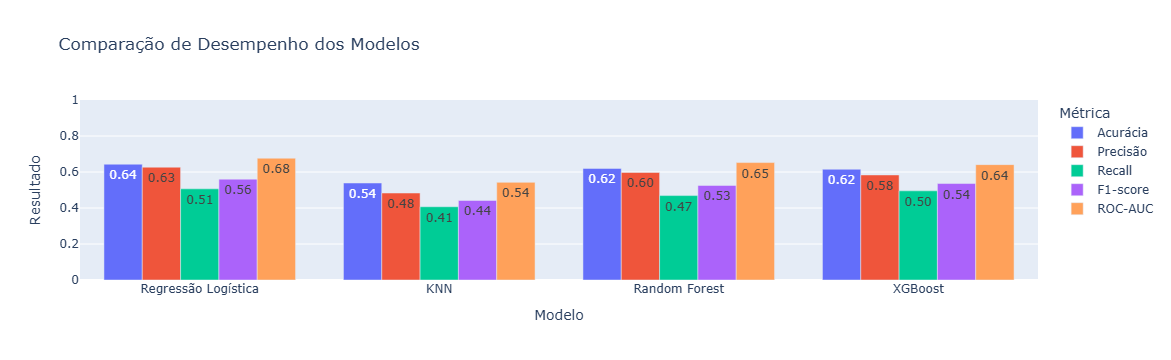

In [53]:
df_comparacao = df_resultados.melt(
    id_vars='Modelo',
    var_name='Métrica',
    value_name='Resultado'
)

fig = px.bar(
    df_comparacao,
    x='Modelo',
    y='Resultado',
    color='Métrica',
    barmode='group',
    title='Comparação de Desempenho dos Modelos',
    text_auto='.2f'
)

fig.update_layout(
    yaxis_title='Resultado',
    xaxis_title='Modelo',
    yaxis_range=[0, 1],
    legend_title='Métrica'
)

fig.show()

### 5.3 Matrizes de Confusão

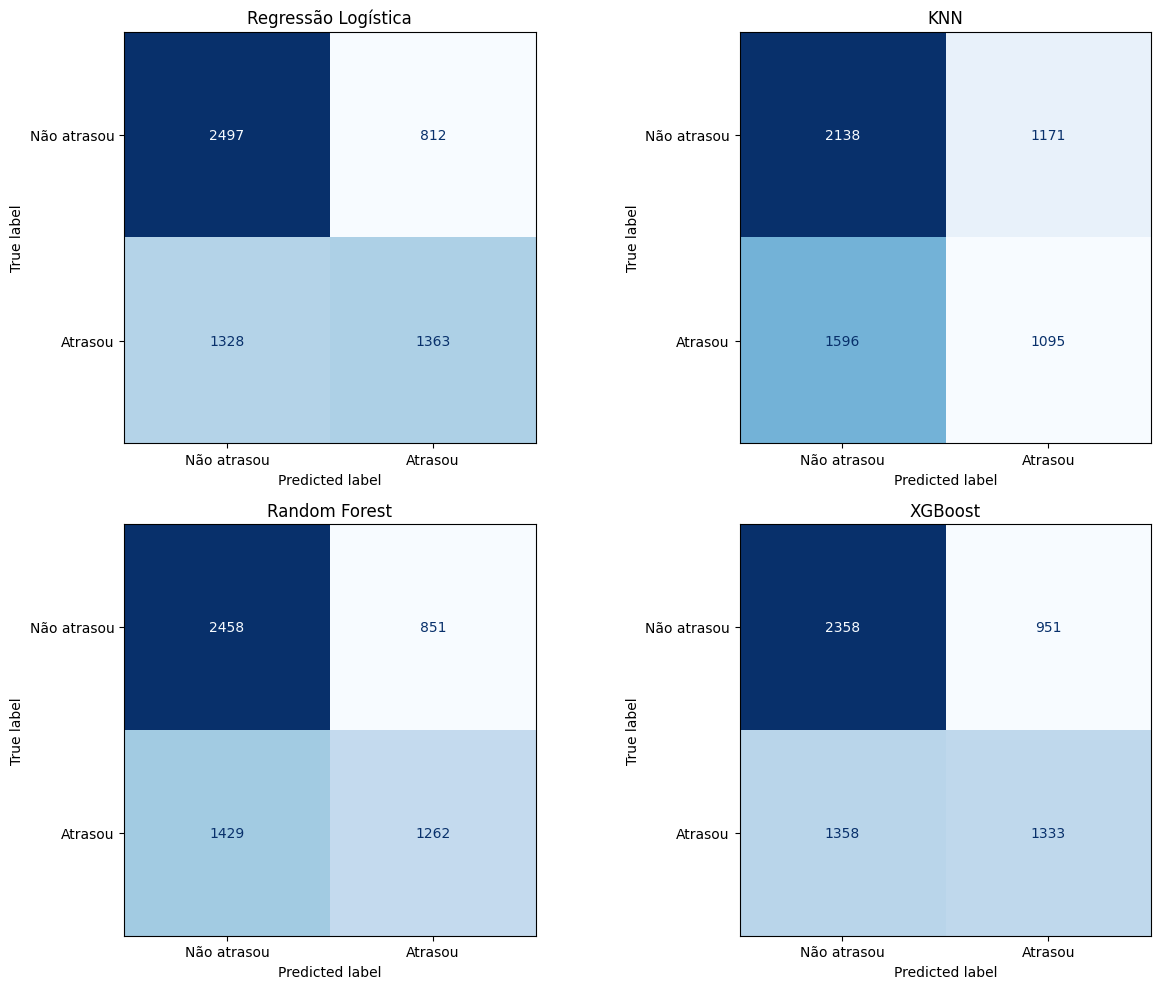

In [55]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for (nome, modelo), ax in zip(modelos.items(), axes.flatten()):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test_transformed,
        y_test,
        display_labels=['Não atrasou', 'Atrasou'],
        values_format='d',
        cmap='Blues',
        colorbar=False,
        ax=ax
    )

    ax.set_title(nome)

plt.tight_layout()
plt.show()

As matrizes de confusão mostram que todos os modelos tiveram alta taxa de falsos negativos, indicando dificuldades na identificação de pedidos que efetivamente sofreram atrasos.

### 5.4 Análise dos Resultados

A partir dos resultados obtidos, observa-se que a Regressão Logística apresentou o melhor desempenho geral, alcançando os maiores valores em todas as métricas analisadas.

O Random Forest apresentou o segundo melhor desempenho em acurácia, precisão e ROC-AUC, enquanto o XGBoost obteve resultados próximos, destacando-se como o segundo melhor modelo em recall e F1-score. 

O KNN apresentou os menores valores na maioria das métricas avaliadas.

Apesar da Regressão Logística ter se destacado, os resultados ainda indicam limitações na capacidade de classificação dos modelos, como foi observado nas matrizes de confusão que evidenciaram uma grande quantidade de falsos negativos.

Então, os resultados indicam a necessidade de investigar possíveis melhorias por meio da otimização dos modelos e do ajuste de seus hiperparâmetros.

### 5.5 Feature Importances

#### 5.5.1 Random Forest

In [56]:
importances_rf = pd.DataFrame({
    'Variavel': preprocessor.get_feature_names_out(),
    'Importancia': model_rf.feature_importances_
})

importances_rf = importances_rf.sort_values(
    by='Importancia',
    ascending=False
)

importances_rf.head(15)

,Variavel,Importancia
64,minmaxscaler__carga_centro_distribuicao_pct,0.097422
62,minmaxscaler__distancia_km,0.092778
65,minmaxscaler__chuva_prevista_mm,0.089658
66,minmaxscaler__lead_time_fornecedor_dias,0.083989
63,minmaxscaler__valor_pedido_brl,0.080410
67,minmaxscaler__dias_prometidos,0.049815
68,remainder__estoque_disponivel,0.019615
41,onehotencoder__congestionamento_rota_Baixo,0.013755
32,onehotencoder__categoria_produto_Moda,0.012942
36,onehotencoder__transportadora_ViaExpress,0.012847


Para o Random Forest, as variáveis de mais importância são: carga_centro_distribuicao_pct, distancia_km, chuva_prevista_mm, lead_time_fornecedor_dias e valor_pedido_brl. As variáveis categóricas aparecem mais abaixo, mas como elas foram transformadas com o enconder, elas foram distribuídas em várias colunas, diferente das variáveis numéricas. Por isso, na etapa a seguir irei somar as importâncias das categorias pertencentes à mesma variável, para analisar se apresentará melhor resultado.

In [58]:
importances_rf['Variavel_original'] = (
    importances_rf['Variavel']
    .str.replace(
        r'^(minmaxscaler__|remainder__)',
        '',
        regex=True
    )
)

for coluna in colunas_categoricas:
    mascara = importances_rf['Variavel'].str.startswith(
        f'onehotencoder__{coluna}_'
    )
    importances_rf.loc[mascara, 'Variavel_original'] = coluna

importances_agrupadas_rf = (
    importances_rf
    .groupby('Variavel_original')['Importancia']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

importances_agrupadas_rf

,Variavel_original,Importancia
0,estado_destino,0.133464
1,mes_pedido,0.104382
2,carga_centro_distribuicao_pct,0.097422
3,distancia_km,0.092778
4,chuva_prevista_mm,0.089658
5,lead_time_fornecedor_dias,0.083989
6,valor_pedido_brl,0.080410
7,dia_semana_pedido,0.074352
8,categoria_produto,0.067935
9,dias_prometidos,0.049815


Segundo essa análise, é possível concluir que o Random Forest utilizou principalmente informações relacionadas à localização, ao período do pedido e às condições logísticas para realizar suas previsões. Porém, essa relação não comprova se realmente uma variável aumenta ou diminui a probabilidade de atraso.

#### 5.5.2 XGBoost

In [60]:
importances_xgb = pd.DataFrame({
    'Variavel': preprocessor.get_feature_names_out(),
    'Importancia': model_xgb.feature_importances_
})

importances_xgb = importances_xgb.sort_values(
    by='Importancia',
    ascending=False
)

importances_xgb.head(15)

,Variavel,Importancia
68,remainder__estoque_disponivel,0.080262
41,onehotencoder__congestionamento_rota_Baixo,0.052824
40,onehotencoder__congestionamento_rota_Alto,0.042372
13,onehotencoder__estado_destino_PA,0.020976
20,onehotencoder__estado_destino_RO,0.020544
2,onehotencoder__estado_destino_AM,0.019787
64,minmaxscaler__carga_centro_distribuicao_pct,0.018632
3,onehotencoder__estado_destino_AP,0.017000
0,onehotencoder__estado_destino_AC,0.016838
5,onehotencoder__estado_destino_CE,0.015773


O XGBoost classificou as variáveis estoque_disponivel, congestionamento_rota_baixo, congestionamento_rota_alto, e alguns estados da região Norte como as mais importantes. E, assim como o Random Forest, cabe analisar as variáveis categóricas agrupadas.

In [63]:
importances_xgb['Variavel_original'] = (
    importances_xgb['Variavel']
    .str.replace(
        r'^(minmaxscaler__|remainder__)',
        '',
        regex=True
    )
)

for coluna in colunas_categoricas:
    mascara = importances_xgb['Variavel'].str.startswith(
        f'onehotencoder__{coluna}_'
    )
    importances_xgb.loc[mascara, 'Variavel_original'] = coluna

importances_agrupadas_xgb = (
    importances_xgb
    .groupby('Variavel_original')['Importancia']
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

importances_agrupadas_xgb

,Variavel_original,Importancia
0,estado_destino,0.377039
1,mes_pedido,0.135951
2,congestionamento_rota,0.104417
3,dia_semana_pedido,0.081230
4,estoque_disponivel,0.080262
5,categoria_produto,0.066367
6,transportadora,0.041247
7,modalidade_envio,0.033438
8,carga_centro_distribuicao_pct,0.018632
9,dias_prometidos,0.013728


Para o XGBoost, a variável de estado_destino tem uma alta importância, passando dos 37%, em comparação com o Random Forest que teve um valor de um pouco mais de 13%. É importante notar que nas etapas de exploração, os estados realmente tiveram uma grande proporção com os atrasos, então esse desempenho do XGBoost pode estar relacionado a isso. 

#### 5.5.3 Regressão Logística

In [65]:
coefs_lr = pd.DataFrame({
    'Variavel': preprocessor.get_feature_names_out(),
    'Coeficiente': model_lr.coef_[0]
})

coefs_lr['Importancia_absoluta'] = (
    coefs_lr['Coeficiente'].abs()
)

coefs_lr = coefs_lr.sort_values(
    by='Importancia_absoluta',
    ascending=False
)

coefs_lr.head(15)

,Variavel,Coeficiente,Importancia_absoluta
64,minmaxscaler__carga_centro_distribuicao_pct,1.815652,1.815652
65,minmaxscaler__chuva_prevista_mm,1.422108,1.422108
62,minmaxscaler__distancia_km,1.402446,1.402446
66,minmaxscaler__lead_time_fornecedor_dias,1.054226,1.054226
68,remainder__estoque_disponivel,-0.953000,0.953000
13,onehotencoder__estado_destino_PA,0.615232,0.615232
41,onehotencoder__congestionamento_rota_Baixo,-0.614541,0.614541
0,onehotencoder__estado_destino_AC,0.424391,0.424391
2,onehotencoder__estado_destino_AM,0.393047,0.393047
23,onehotencoder__estado_destino_SC,-0.379694,0.379694


Algumas características da Regressão são semelhantes ao que foi visto no RF, como a carga, a chuva e a distância. Além disso, nota-se que a Regressão também levou em conta o estado do destino como importância, assim como observou-se no XGBoost. Portanto, mesmo utilizando abordagens diferentes, os modelos identificaram algumas características recorrentes.

## 6. Otimização dos Modelos

### 6.1 Ajuste de Hiperparâmetros

In [68]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#### 6.1.1 Regressão Logística

In [69]:
pipeline_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

parametros_lr = {
    'model__C': [0.01, 0.1, 1, 10, 100],
    'model__class_weight': [None, 'balanced']
}

grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=parametros_lr,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_lr.fit(X_train, y_train)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced']}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('onehotencoder', ...), ('minmaxscaler', ...)]"


In [70]:
print('Melhores parâmetros:', grid_lr.best_params_)
print('Melhor recall médio:', grid_lr.best_score_)

Melhores parâmetros: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Melhor recall médio: 0.6169838662055367


In [71]:
model_lr_otimizado = grid_lr.best_estimator_

#### 6.1.2 Random Forest

In [72]:
pipeline_rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=42
    ))
])

parametros_rf = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5]
}

In [73]:
grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf,
    scoring='recall',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 10, ...], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('onehotencoder', ...), ('minmaxscaler', ...)]"


In [74]:
print('Melhores parâmetros:', grid_rf.best_params_)
print('Melhor recall médio:', grid_rf.best_score_)

Melhores parâmetros: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Melhor recall médio: 0.4843892934040338


In [79]:
model_rf_otimizado = grid_rf.best_estimator_

#### 6.1.3 XGBoost

In [76]:
pipeline_xgb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBClassifier(
        random_state=42,
        eval_metric='logloss',
        n_jobs=2
    ))
])

parametros_xgb = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [3, 5],
    'model__learning_rate': [0.05, 0.1]
}

In [77]:
grid_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=parametros_xgb,
    scoring='recall',
    cv=cv,
    n_jobs=2,
    verbose=1
)

grid_xgb.fit(X_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_grid,"{'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5], 'model__n_estimators': [100, 200]}"
,scoring,'recall'
,n_jobs,2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('onehotencoder', ...), ('minmaxscaler', ...)]"


In [78]:
print('Melhores parâmetros:', grid_xgb.best_params_)
print('Melhor recall médio:', grid_xgb.best_score_)

Melhores parâmetros: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
Melhor recall médio: 0.49377370902881257


In [81]:
model_xgb_otimizado = grid_xgb.best_estimator_

#### 6.1.4 KNN

In [82]:
pipeline_knn = Pipeline([
    ('preprocessor', preprocessor),
    ('model', KNeighborsClassifier())
])

parametros_knn = {
    'model__n_neighbors': [5, 7, 9],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2]
}

In [83]:
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=parametros_knn,
    scoring='recall',
    cv=cv,
    n_jobs=2,
    verbose=1
)

grid_knn.fit(X_train, y_train)

Fitting 5 folds for each of 12 candidates, totalling 60 fits


,estimator,Pipeline(step...lassifier())])
,param_grid,"{'model__n_neighbors': [5, 7, ...], 'model__p': [1, 2], 'model__weights': ['uniform', 'distance']}"
,scoring,'recall'
,n_jobs,2
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('onehotencoder', ...), ('minmaxscaler', ...)]"


In [84]:
print('Melhores parâmetros:', grid_knn.best_params_)
print('Melhor recall médio:', grid_knn.best_score_)

Melhores parâmetros: {'model__n_neighbors': 5, 'model__p': 2, 'model__weights': 'distance'}
Melhor recall médio: 0.4150715609066281


In [85]:
model_knn_otimizado = grid_knn.best_estimator_

### 6.2 Comparação dos Resultados

In [89]:
resultados_otimizados = []

for nome, modelo in modelos_otimizados.items():
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    resultados_otimizados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

df_resultados_otimizados = pd.DataFrame(resultados_otimizados)

df_resultados_otimizados

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC-AUC
0,Regressão Logística,0.632500,0.586354,0.613155,0.599455,0.676203
1,KNN,0.537167,0.481272,0.410628,0.443152,0.541136
2,Random Forest,0.624500,0.601108,0.483835,0.536133,0.660829
3,XGBoost,0.638500,0.621735,0.495355,0.551396,0.669913


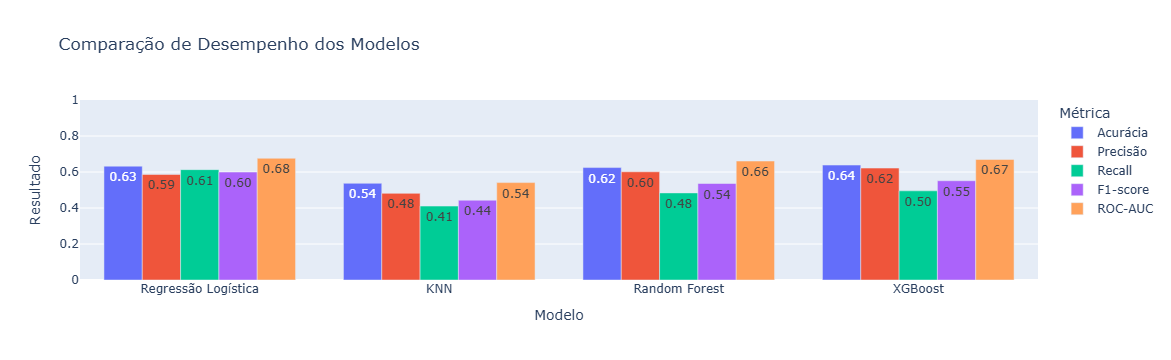

In [91]:
df_comparacao_otimizado = df_resultados_otimizados.melt(
    id_vars='Modelo',
    var_name='Métrica',
    value_name='Resultado'
)

fig = px.bar(
    df_comparacao_otimizado,
    x='Modelo',
    y='Resultado',
    color='Métrica',
    barmode='group',
    title='Comparação de Desempenho dos Modelos',
    text_auto='.2f'
)

fig.update_layout(
    yaxis_title='Resultado',
    xaxis_title='Modelo',
    yaxis_range=[0, 1],
    legend_title='Métrica'
)

fig.show()

Após a otimização dos modelos, ajustando os hiperparâmetros, concluí-se que:
- Regressão Logística melhorou considerávelmente seu desempenho (principamente seu Recall que era de 50.63% e agora 61.32%) e ainda se mantém como o melhor modelo.
- XGBoost superou o Random Forest e ainda se destaca nas métricas de Acurácia e Precisão.
- Random Forest apresentou resultados intermediários, enquanto o KNN continuou registrando o menor desempenho entre os modelos avaliados.

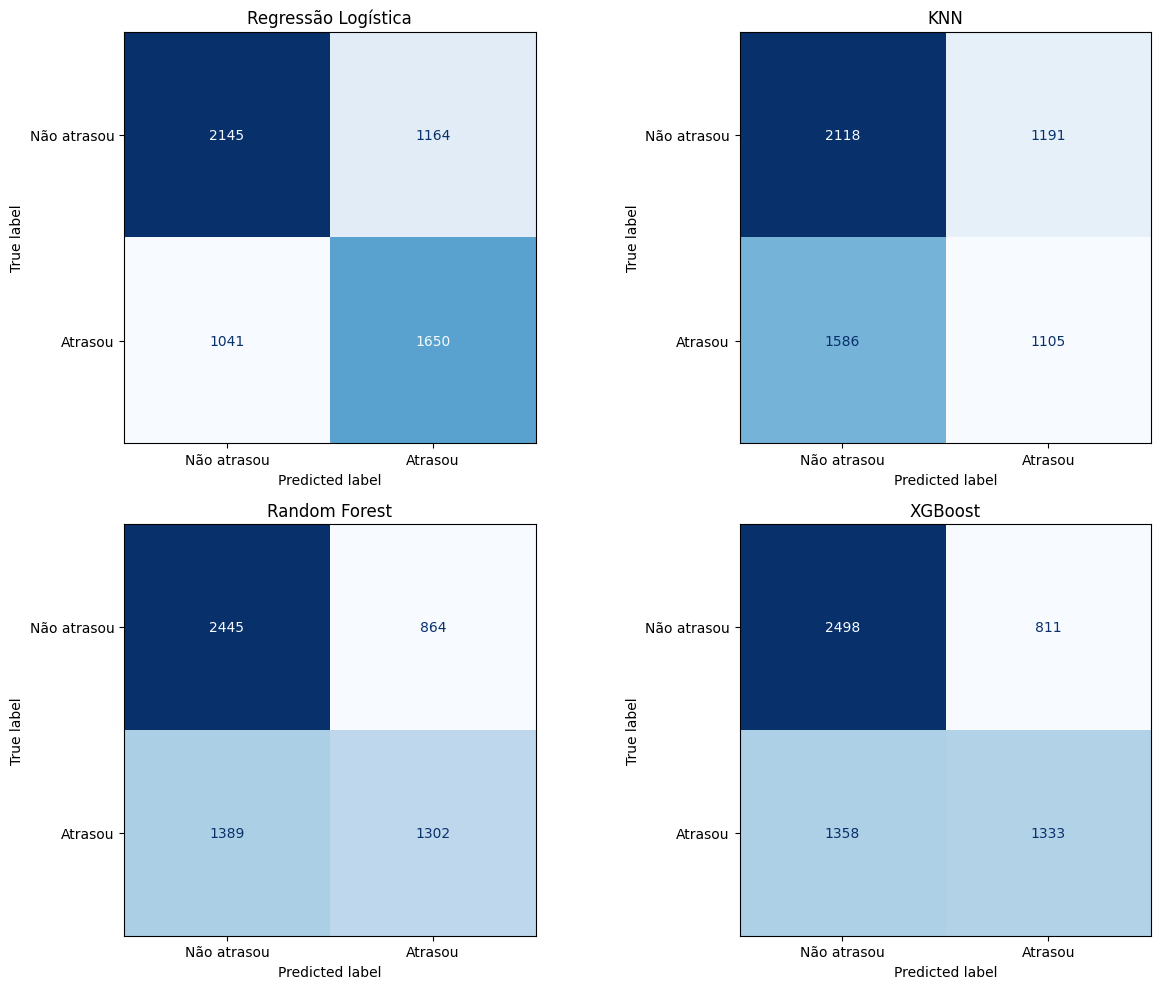

In [93]:
modelos_otimizados = {
    'Regressão Logística': grid_lr.best_estimator_,
    'KNN': grid_knn.best_estimator_,
    'Random Forest': grid_rf.best_estimator_,
    'XGBoost': grid_xgb.best_estimator_
}

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for (nome, modelo), ax in zip(modelos_otimizados.items(), axes.flatten()):
    ConfusionMatrixDisplay.from_estimator(
        modelo,
        X_test,
        y_test,
        display_labels=['Não atrasou', 'Atrasou'],
        values_format='d',
        cmap='Blues',
        colorbar=False,
        ax=ax
    )

    ax.set_title(nome)

plt.tight_layout()
plt.show()

Analisando a Matriz gerada e comparando com os resultados após a otimização, percebe-se que a otimização fez a Regressão Logística identificar 287 pedidos atrasados a mais, mas também gerou 352 falsos positivos adicionais. Demonstrando o trade-off entre precisão e recall, que ao tentar identificar mais pedidos atrasados, o modelo também passou a classificar mais pedidos que não atrasariam como potenciais atrasos.

Apesar disso, o modelo escolhido será a Regressão Logística, pois possui melhor desempenho nas demais métricas, e poderá ser avaliada posteriormente quanto a ocorrência desses valores de falsos positivos.

## 7. Conclusões

### 7.1 Principais Resultados

Na análise exploratória foi identificado que:
- Quanto maior a distância, menor é a ocorrência de pedidos;
- A porcentagem de pedidos com atraso totaliza 44,8%, indicando uma distribuição equilibrada entre as classes, mas um alto número de atrasos;
- Variáveis como carga, centro de distribuição, dias prometidos e distância tiveram correlações, mesmo que baixas, com a variável alvo.

Na avaliação inicial dos modelos foi identificado que:
- A Regressão Logística obteve os maiores resultados em todas as métricas avaliadas;
- As matrizes de confusão evidenciaram grande quantidade de falsos negativos nos modelos, indicando dificuldades na identificação de pedidos que efetivamente atrasaram.

Após a otimização de hiperparâmetros, identificou-se que:
- A Regressão melhorou seu desempenho, com Recall de 61,32%, além de obter melhores resultados em F1-Score e ROC-AUC;
- O XGBoost apresentou maiores resultados na Acurácia e na Precisão;
- O Random Forest apresentou resultados intermediários;
- O KNN foi o algoritmo menos preciso tanto na primeira avaliação quanto após a otimização;
- As matrizes de confusão demonstraram que a Regressão passou a identificar mais pedidos atrasados, mas também gerou falsos positivos adicionais aos da primeira avaliação, evidenciando o trade-off entre precisão e recall.

Diante dos resultados, o modelo escolhido foi a Regressão Logística, por ter apresentado maior capacidade de identificação de pedidos atrasado. Porém, seu desempenho possui limitações que serão discutidas na seção de melhorias.

### 7.2 Limitações do Estudo

- A base de dados é sintética e não pode representar completamente as características e os desafios de uma operação logística real;
- Não foi possível determinar com precisão o momento em que cada variável se torna disponível, o que pode limitar a aplicação dos modelos em um cenário de previsão antecipada;
- Os modelos apresentaram desempenho moderado, indicando que ainda existem dificuldades na identificação de pedidos que efetivamente apresentarão atrasos;
- Embora tenham sido identificados possíveis outliers durante a análise exploratória, não foi realizado um tratamento específico, nem avaliado seu impacto no desempenho dos modelos.

### 7.3 Possíveis Melhorias

- Utilizar uma base de dados real, para avaliar os resultados em um cenário mais próximo do mercado;
- Analisar outros valores para encontrar um equilíbrio mais adequado entre precisão e recall, pois no momento utiliza-se o limiar padrão de 0,5 para classificar os pedidos;
- Investigar os erros dos modelos, procurando identificar quais características aparecem com maior frequência nos pedidos classificados incorretamente;
- Utilizar validação temporal ao testar os modelos treinando com períodos anteriores e avaliando em períodos posteriores.